# S01a — Découvrir PySpark sur NYC Taxi

1. Démarrer Spark et repérer la **Spark UI** (http://localhost:4040)
2. Lire un mois de courses et comprendre son schéma
3. Comprendre l'**évaluation paresseuse** : transformations vs actions
4. Joindre le référentiel des zones et agréger
5. Ramener un petit résultat en pandas pour un premier graphique

Prérequis : `bash scripts/telecharger_donnees.sh` a été lancé (fichiers dans `data/raw/`).

In [5]:
import sys; sys.path.append("/home/jovyan/work")
from pyspark.sql import functions as F
from commun.spark_utils import creer_session, RAW, LAKE

# Ici Spark seul : pas encore de data lake ni de base de données
spark = creer_session("S01a", lac=False, delta=False, postgres=False)

Préparation de Spark 4.2.0 (Hadoop 3.5.0) … le premier démarrage peut prendre quelques minutes.
Session prête. Spark UI : http://localhost:4040


## 1. Lire les données

In [9]:
MOIS = "2025-01"
trips = spark.read.parquet(f"{RAW}/yellow_tripdata_{MOIS}.parquet")
trips.printSchema()

root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



In [10]:
# Une ACTION : Spark calcule vraiment (onglet Jobs de la Spark UI)
print(f"{trips.count():,} courses")
trips.limit(5).toPandas()

3,475,226 courses


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1,1.60,1,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1,0.50,1,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1,0.60,1,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3,0.52,1,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3,0.66,1,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


## 2. Évaluation paresseuse

Une **transformation** (`filter`, `select`, `withColumn`, `groupBy`…) ne calcule rien : Spark note le plan.
Une **action** (`count`, `show`, `toPandas`, `write`…) exécute tout le plan.
La cellule suivante est instantanée et aucun job n'apparaît dans la Spark UI.

In [11]:
longues = (trips
           .filter(F.col("trip_distance") > 20)
           .select("tpep_pickup_datetime", "trip_distance", "total_amount"))
longues.explain()     # le plan, pas le résultat

== Physical Plan ==
*(1) Filter (isnotnull(trip_distance#4) AND (trip_distance#4 > 20.0))
+- *(1) ColumnarToRow
   +- FileScan parquet [tpep_pickup_datetime#1,trip_distance#4,total_amount#16] Batched: true, DataFilters: [isnotnull(trip_distance#4), (trip_distance#4 > 20.0)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/home/jovyan/work/data/raw/yellow_tripdata_2025-01.parquet], PartitionFilters: [], PushedFilters: [IsNotNull(trip_distance), GreaterThan(trip_distance,20.0)], ReadSchema: struct<tpep_pickup_datetime:timestamp_ntz,trip_distance:double,total_amount:double>




In [12]:
longues.count()      # maintenant seulement, Spark calcule

28289

In [13]:
longues.limit(10).toPandas()      # maintenant seulement, Spark calcule

,tpep_pickup_datetime,trip_distance,total_amount
0,2025-01-01 00:04:29,31.97,111.32
1,2025-01-01 00:23:05,22.00,91.89
2,2025-01-01 00:49:36,24.70,-123.44
3,2025-01-01 00:49:36,24.70,123.44
4,2025-01-01 00:45:34,20.21,99.23
5,2025-01-01 00:05:17,29.61,190.23
6,2025-01-01 00:35:40,29.40,192.40
7,2025-01-01 00:08:31,27.11,151.35
8,2025-01-01 00:47:02,20.65,97.74
9,2025-01-01 00:11:07,31.71,183.35


## 3. Joindre le référentiel des zones

`PULocationID` / `DOLocationID` = zones de départ / d'arrivée (1 à 265).

In [15]:
zones = spark.read.csv(f"{RAW}/taxi_zone_lookup.csv", header=True, inferSchema=True)
zones.show(5)

trips_z = trips.join(
    zones.select(F.col("LocationID").alias("PULocationID"),
                 F.col("Borough").alias("pu_borough"),
                 F.col("Zone").alias("pu_zone")),
    on="PULocationID", how="left")

+----------+-------------+--------------------+------------+
|LocationID|      Borough|                Zone|service_zone|
+----------+-------------+--------------------+------------+
|         1|          EWR|      Newark Airport|         EWR|
|         2|       Queens|         Jamaica Bay|   Boro Zone|
|         3|        Bronx|Allerton/Pelham G...|   Boro Zone|
|         4|    Manhattan|       Alphabet City| Yellow Zone|
|         5|Staten Island|       Arden Heights|   Boro Zone|
+----------+-------------+--------------------+------------+
only showing top 5 rows


## 4. Premiers agrégats

In [16]:
par_heure = (trips_z
             .withColumn("heure", F.hour("tpep_pickup_datetime"))
             .groupBy("heure")
             .agg(F.count("*").alias("courses"),
                  F.round(F.sum("total_amount"), 0).alias("revenu_total"),
                  F.round(F.avg("tip_amount"), 2).alias("pourboire_moyen"))
             .orderBy("heure"))
par_heure.show(24)

+-----+-------+------------+---------------+
|heure|courses|revenu_total|pourboire_moyen|
+-----+-------+------------+---------------+
|    0|  93417|   2371983.0|           2.66|
|    1|  64484|   1504284.0|           2.36|
|    2|  43929|    973495.0|           2.21|
|    3|  28492|    644218.0|           2.25|
|    4|  20033|    560345.0|           2.67|
|    5|  22551|    714343.0|           3.02|
|    6|  50026|   1356957.0|           2.53|
|    7| 102581|   2599478.0|           2.56|
|    8| 141305|   3410758.0|           2.55|
|    9| 142877|   3496776.0|            2.9|
|   10| 148316|   3672648.0|           3.05|
|   11| 160076|   3927036.0|           3.03|
|   12| 175432|   5206861.0|           3.04|
|   13| 186144|   4715047.0|           3.14|
|   14| 202289|   5268654.0|           3.21|
|   15| 213694|   5573590.0|           3.22|
|   16| 217051|   6029906.0|           3.44|
|   17| 253518|   6565618.0|           3.08|
|   18| 267951|   6566541.0|            2.8|
|   19| 22

In [17]:
(trips_z.groupBy("pu_borough")
        .agg(F.count("*").alias("courses"), F.round(F.avg("total_amount"), 2).alias("prix_moyen"))
        .orderBy(F.desc("courses"))
        .show())

+-------------+-------+----------+
|   pu_borough|courses|prix_moyen|
+-------------+-------+----------+
|    Manhattan|3089275|     21.72|
|       Queens| 294986|     65.32|
|     Brooklyn|  66070|     27.12|
|        Bronx|  14741|     31.34|
|      Unknown|   8141|     27.67|
|          N/A|   1380|     89.56|
|          EWR|    377|     94.34|
|Staten Island|    256|     36.24|
+-------------+-------+----------+



## 5. Qualité des données

Ces anomalies seront traitées en S02 (couche *silver*).

In [18]:
import datetime as dt
a, m = map(int, MOIS.split("-"))
debut, fin = f"{MOIS}-01", dt.date(a + (m == 12), m % 12 + 1, 1).isoformat()

trips.select(
    F.sum((F.col("total_amount") < 0).cast("int")).alias("montant_negatif"),
    F.sum(((F.col("passenger_count") == 0) | F.col("passenger_count").isNull()).cast("int")).alias("passagers_0_ou_vide"),
    F.sum((F.col("trip_distance") > 100).cast("int")).alias("distance_sup_100_miles"),
    F.sum(((F.col("tpep_pickup_datetime") < F.lit(debut)) |
           (F.col("tpep_pickup_datetime") >= F.lit(fin))).cast("int")).alias("hors_du_mois"),
).show()

+---------------+-------------------+----------------------+------------+
|montant_negatif|passagers_0_ou_vide|distance_sup_100_miles|hors_du_mois|
+---------------+-------------------+----------------------+------------+
|          63037|             564805|                   162|          22|
+---------------+-------------------+----------------------+------------+



## 6. Du résultat Spark au graphique

On agrège dans Spark, puis on ramène **un petit résultat** en pandas. Jamais `trips.toPandas()` sur des millions de lignes.

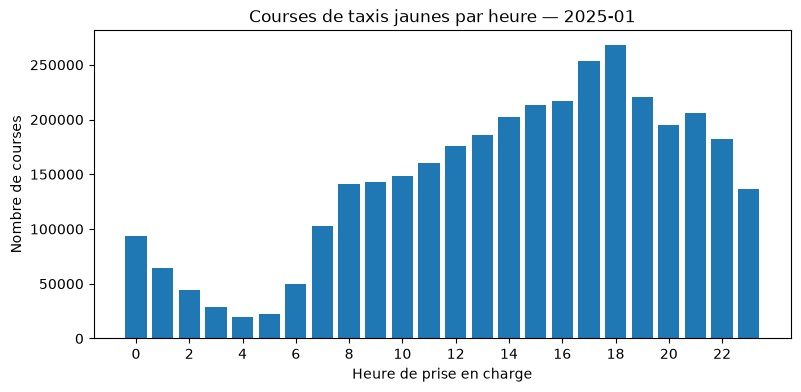

In [19]:
import matplotlib.pyplot as plt
pdf = par_heure.toPandas()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pdf["heure"], pdf["courses"])
ax.set_xlabel("Heure de prise en charge"); ax.set_ylabel("Nombre de courses")
ax.set_title(f"Courses de taxis jaunes par heure — {MOIS}")
ax.set_xticks(range(0, 24, 2))
plt.show()

## À retenir
- Spark calcule en parallèle ; la Spark UI montre jobs et tâches.
- Transformations = plan ; actions = exécution.
- On agrège dans Spark, on visualise un petit résultat.

**Exercice :** quelle zone de départ a le revenu moyen par course le plus élevé ? Est-ce un aéroport ?

In [ ]:
spark.stop()